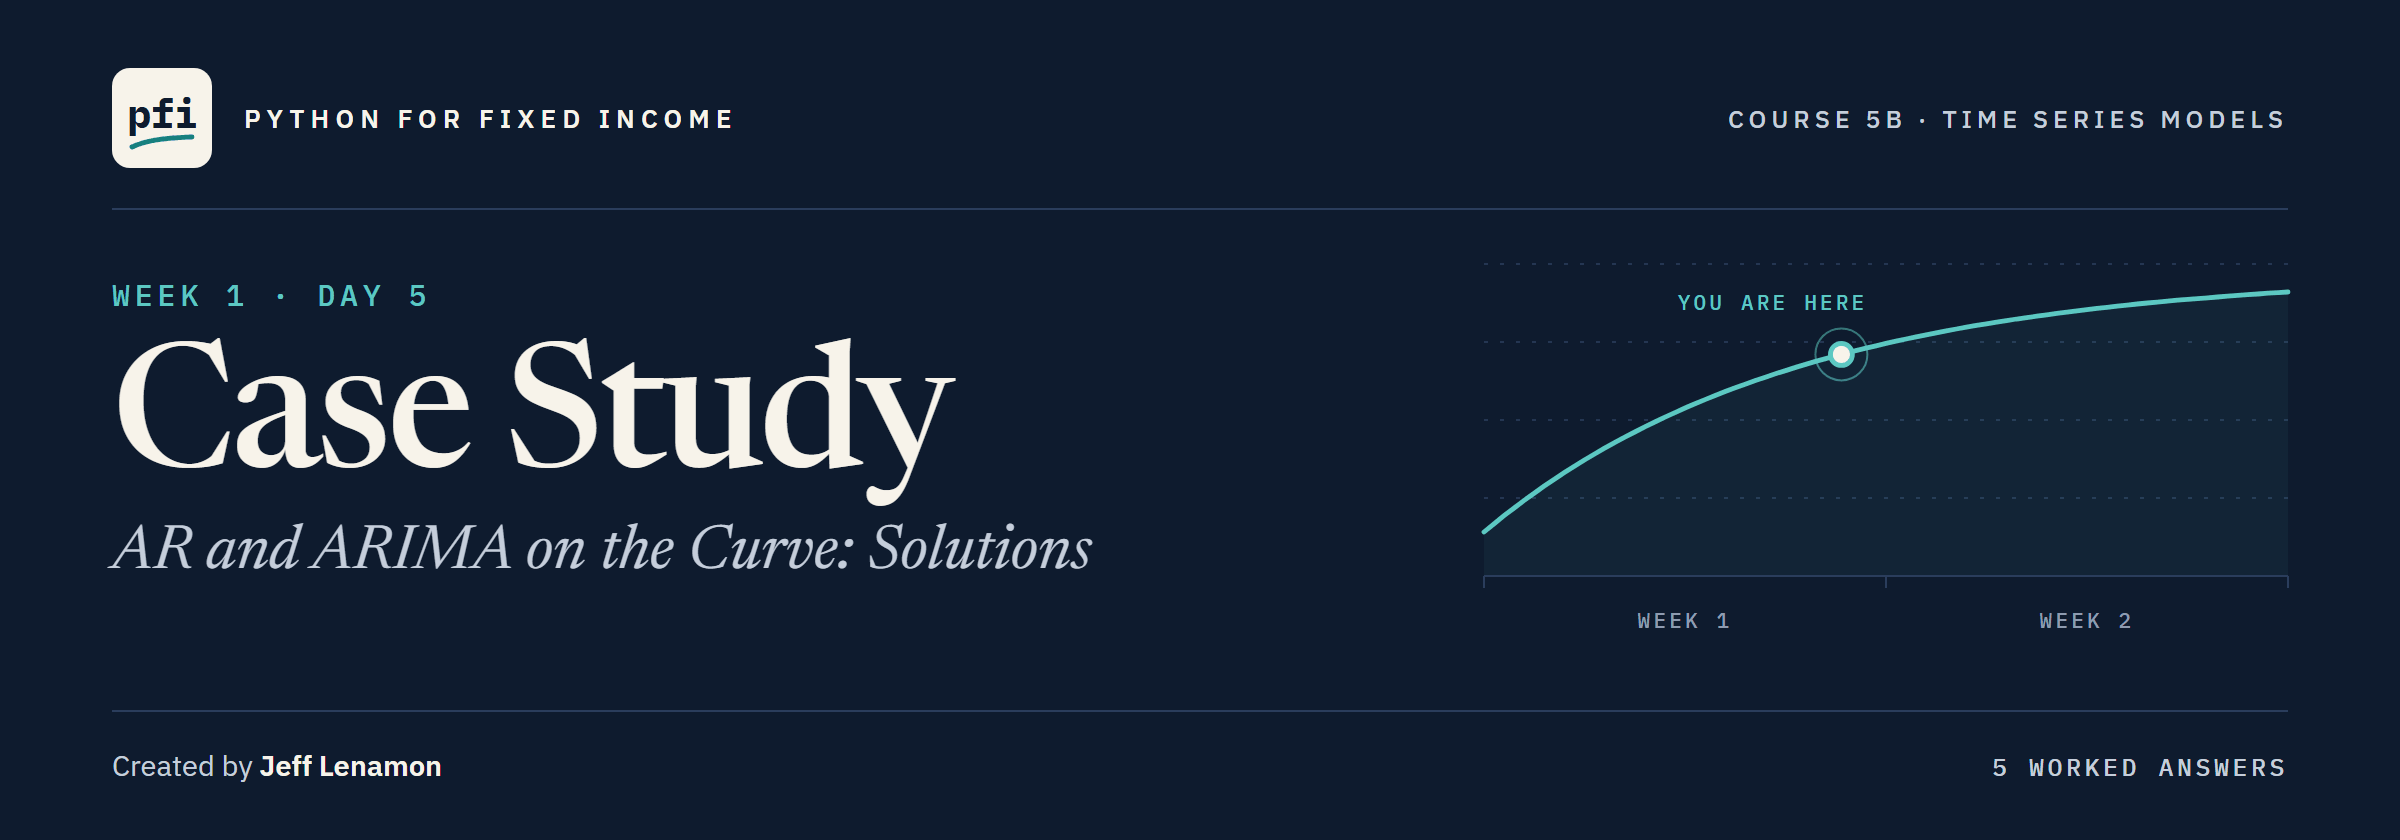

# Case Study: AR and ARIMA on the Curve: Solutions

Week 1, Day 5. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week1/day5/05_case_study_ar_and_arima_on_the_curve_solutions.ipynb)

# Problem Statement

## Business Context

Day 4 found a little memory in the daily changes and a lot in their size.
The desk now wants to know, for the curve and for credit, whether a model that remembers past changes, past surprises, or both gets closer to each date's change than Day 2's last value carried forward.
We work it through on the 10 Yr, then run the same workflow as a case study on the 10 Yr, the 2s10s slope and the synthetic IG spread.
Textbooks name these forecasting models, but here every output is a one-step value for a date inside the file and never a forecast of rates or spreads.
The held-out years stay closed.

## Objectives

Fit an AR(1) by least squares and by maximum likelihood, read phi with its standard error, and take one-step values on test dates.
Set ARIMA's order and trend, choose an order with AIC and BIC over a grid, read each fit's convergence flag and roots, and check its residuals.
Walk ARIMA forward on Day 2's folds, score it with MASE on three series, and say what the models show and where they fail.

## Data Dictionary

`treasury_par_yields.csv`, one row per trading day:

1. `date`: the trading day, 2015-01-02 to 2026-10-02
2. `2 Yr`, `10 Yr`: par yields, percent (the other twelve tenors are not used today)

`course3_synthetic_spreads.csv`, one row per trading day of the Treasury file:

1. `ig_spread_bp`, `hy_spread_bp`: investment grade and high yield spreads, bp

Made in the notebook, as on Day 2: the five series in bp and their daily changes.
The case study uses the `10 Yr`, `2s10s` and `IG` changes.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# the models and their checks, from statsmodels
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

# the normal Q-Q plot, Day 2's folds, and the MAE in bp
from scipy import stats
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error

# the one statsmodels warning a cell may meet by name: a mixed order's starting values
import warnings
from statsmodels.tools.sm_exceptions import EstimationWarning

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

# Loading the Data

## Day 2's Five Series in bp

Today fits and scores inside the development years only.

In [3]:
# the Treasury par yields in percent and the synthetic spreads in bp, one row per trading day
yields = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")
spreads = pd.read_csv(DATA + "course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date")

# Day 2's cut: the development years only, so the held-out years stay closed
CUT = "2022-12-30"
development = yields.loc[:CUT]

In [4]:
# Day 2's five series, all in bp: a yield in percent times 100, the slope as 10 Yr less 2 Yr
levels = pd.DataFrame({"2 Yr": (development["2 Yr"] * 100).round(2),
                       "10 Yr": (development["10 Yr"] * 100).round(2),
                       "2s10s": ((development["10 Yr"] - development["2 Yr"]) * 100).round(2),
                       "IG": spreads.loc[:CUT, "ig_spread_bp"],
                       "HY": spreads.loc[:CUT, "hy_spread_bp"]})

# each day's change in bp: the level less the level one row before
changes = levels.diff().dropna()
print(len(levels), "levels and", len(changes), "changes, from", changes.index[0].date(), "to", changes.index[-1].date())

2001 levels and 2000 changes, from 2015-01-05 to 2022-12-30


# Data Overview

## The Three Changes

In [5]:
# the case study's three series: the 10 Yr, the 2s10s slope and the synthetic IG spread
three = changes[["10 Yr", "2s10s", "IG"]]
overview = three.describe().T[["mean", "std", "min", "max"]]
overview["mean size"] = three.abs().mean()
overview["days with no change"] = (three == 0).sum()
overview

,mean,std,min,max,mean size,days with no change
10 Yr,0.0880,5.0285,-30.0000,29.0000,3.7480,192
2s10s,-0.0995,3.3230,-16.0000,18.0000,2.4365,311
IG,0.0165,1.1890,-7.0000,9.8000,0.8438,71


A typical day moves the 10 Yr by 3.75 bp, the 2s10s by 2.44 and IG by 0.84.

On the 192, 311 and 71 days with no change, carrying the last value forward is exact.

**Three complete series of changes, each centred near zero.**

# Exploratory Data Analysis

## Memory in Each Series

Day 4 counted a bar as memory only outside the band, plus or minus 1.96 / sqrt(n), where noise puts about one bar in twenty.
Its Ljung-Box test rejected "no memory" at 10 lags for the 10 Yr and IG, and the squared changes remembered on every series.

In [6]:
# each series' ACF to lag 20, Day 4's band, and Ljung-Box's p-value at 10 lags
band = 1.96 / np.sqrt(len(three))
bars = {name: acf(three[name].to_numpy(), nlags=20)[1:] for name in three}
for name in three:
    p_value = acorr_ljungbox(three[name].to_numpy(), lags=[10])["lb_pvalue"].iloc[0]
    print(name, "| lag 1:", round(bars[name][0], 4), "| outside the band:", int((np.abs(bars[name]) > band).sum()),
          "of 20 | Ljung-Box p, 10 lags:", round(p_value, 4))

10 Yr | lag 1: -0.0075 | outside the band: 2 of 20 | Ljung-Box p, 10 lags: 0.0225
2s10s | lag 1: -0.0219 | outside the band: 2 of 20 | Ljung-Box p, 10 lags: 0.1461
IG | lag 1: -0.0486 | outside the band: 5 of 20 | Ljung-Box p, 10 lags: 0.0024


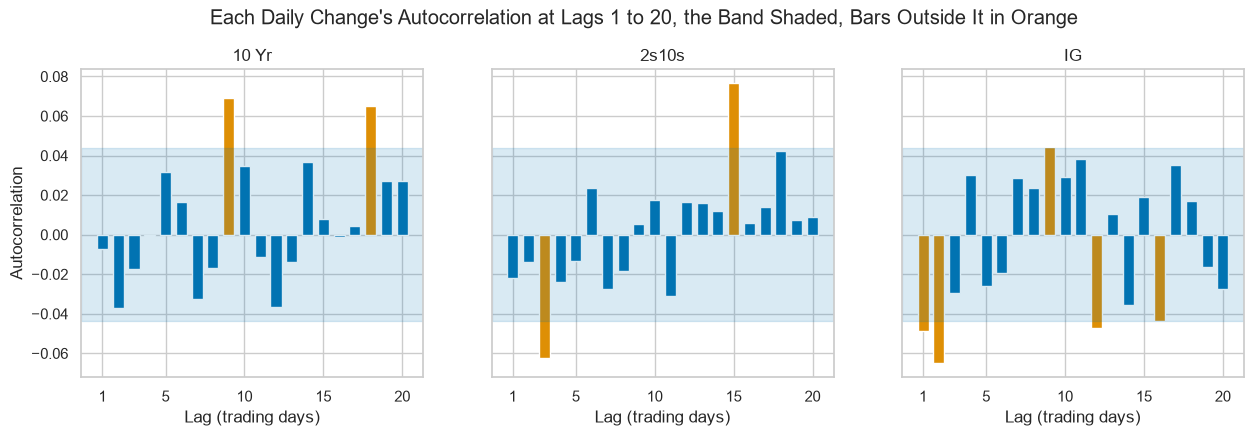

In [7]:
# the three ACFs as bars, Day 4's band shaded, bars outside it in orange
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes, three):
    ax.bar(range(1, 21), bars[name], width=0.7, color=["C1" if abs(b) > band else "C0" for b in bars[name]])
    ax.axhspan(-band, band, color="C0", alpha=0.15)
    ax.set(title=name, xlabel="Lag (trading days)", xticks=[1, 5, 10, 15, 20])
axes[0].set_ylabel("Autocorrelation")
fig.suptitle("Each Daily Change's Autocorrelation at Lags 1 to 20, the Band Shaded, Bars Outside It in Orange", y=1.03)
plt.show()

Every lag-1 bar is under 0.05 in size, and every bar to lag 20 under 0.08.

At 10 lags the 10 Yr and IG reject "no memory" at 5 percent and the 2s10s does not, though Day 4 found it rejects at 3 lags and again from 15.

**At 10 lags two of the three series hold memory a test can see. Today asks whether a model can use it.**

# Data Preparation for Modeling

## Day 2's Folds and the Bar

Day 2's five folds, repeated: each trains on every change before its 252 test dates.
The last value's fitted change is 0, so its miss on a test date is that date's change.

In [8]:
# Day 2's five folds: row positions for training, then for testing
folds = list(TimeSeriesSplit(n_splits=5, test_size=252).split(changes))

# the last value's MAE in bp on each fold's test dates: the average size of the change there
last_value = pd.DataFrame({f"fold {k}": three.iloc[test_rows].abs().mean()
                           for k, (fit_rows, test_rows) in enumerate(folds, start=1)}).T
print("Average:", last_value.mean().round(3).to_dict())
print("Fold range:", (last_value.max() - last_value.min()).round(3).to_dict())
last_value

Average: {'10 Yr': 3.872, '2s10s': 2.567, 'IG': 0.912}
Fold range: {'10 Yr': 3.567, '2s10s': 2.194, 'IG': 0.474}


,10 Yr,2s10s,IG
fold 1,2.6905,1.8214,0.7349
fold 2,3.4444,1.6468,0.8448
fold 3,3.6627,2.7222,0.7603
fold 4,3.3056,2.8016,1.0115
fold 5,6.2579,3.8413,1.2087


Day 2's numbers: the last value misses the 10 Yr by 3.872 bp a date on average, the 2s10s by 2.567 and IG by 0.912.

The folds disagree by 3.567, 2.194 and 0.474 bp.

**Every model below is fitted once a fold on the dates before it, and must beat these numbers by more than the folds disagree.**

# Model Building: An AR(1)

![An AR(1)'s one-step value for a test date t. The training dates are fitted once a fold to give the constant c and phi, the change on the row before, t-1, supplies the rest, and the value for t is c plus phi times the change on t-1. The change on t itself, drawn dashed, is never read](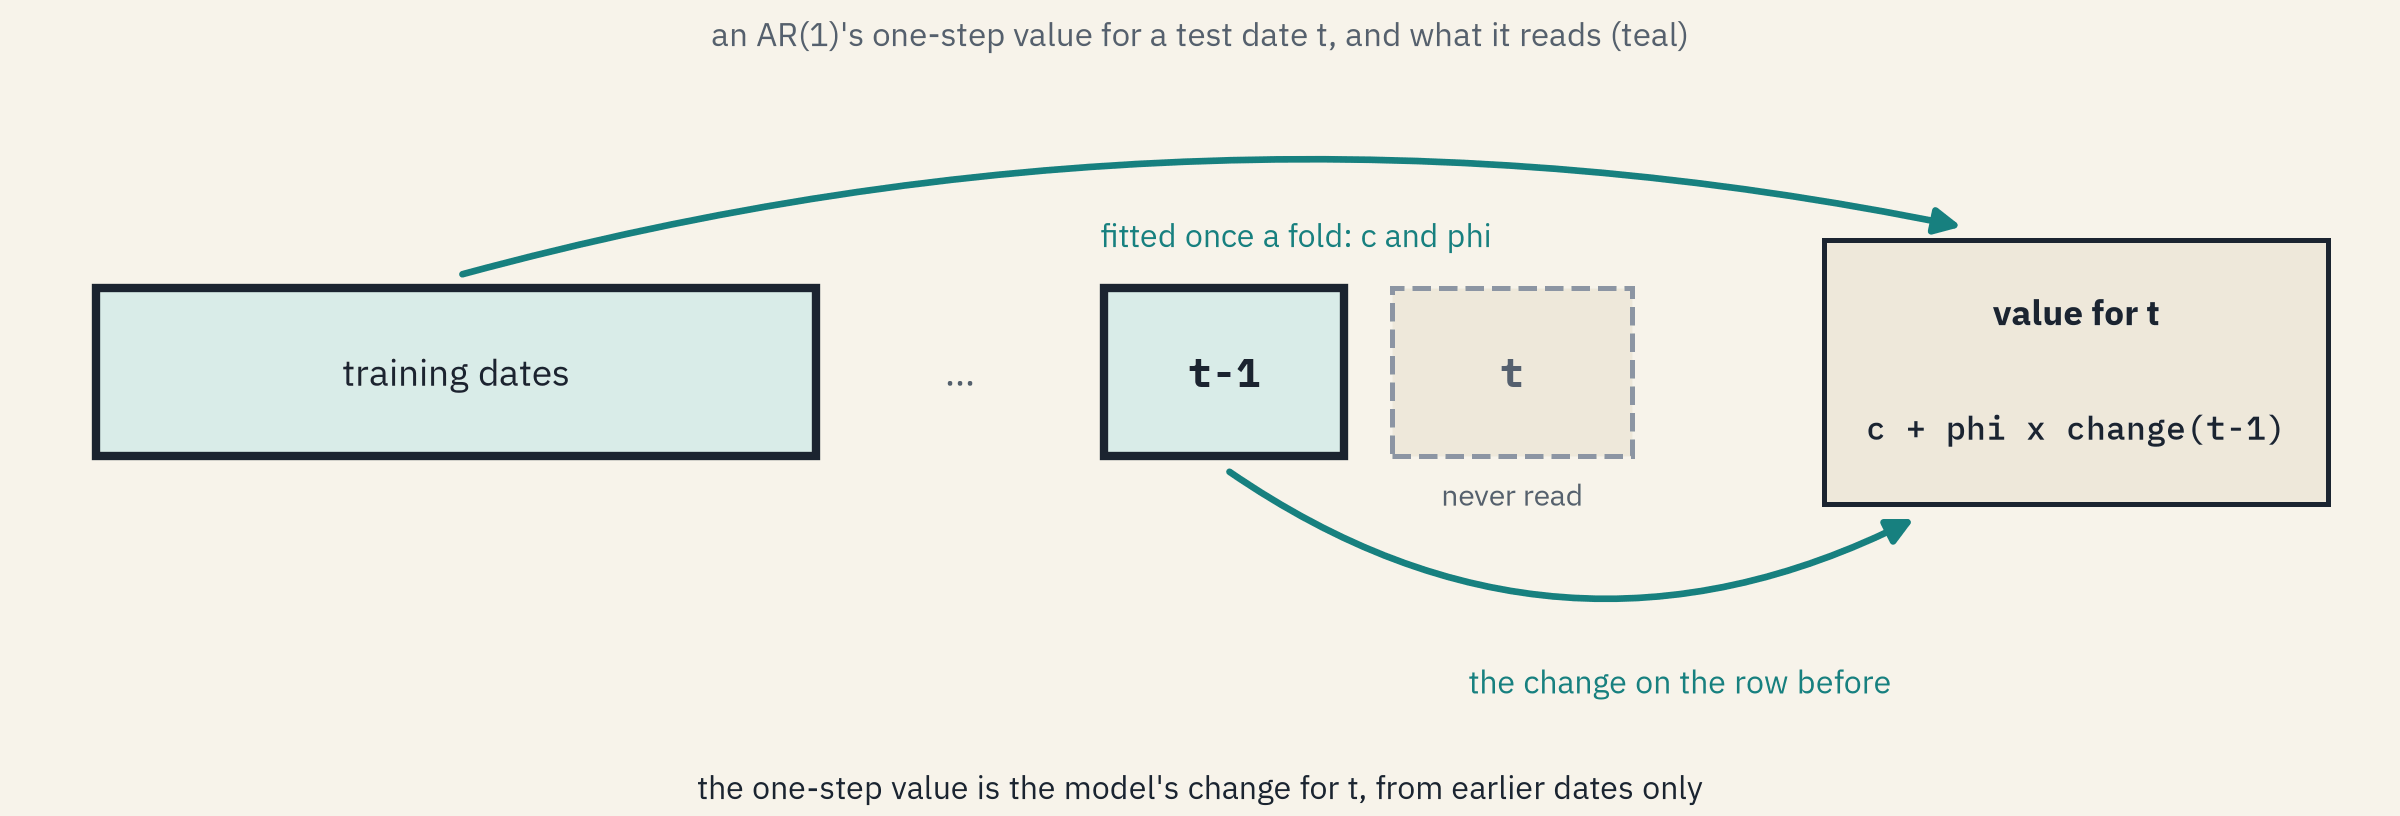)

Day 3's AR(1), with a constant c: a change is c plus phi times the change on the row before, plus a shock.
Fitting finds c and phi from the training dates.
A **one-step value** for a date is c plus phi times the change on the row before: the model's value for that date from earlier dates only.

## Fitting Phi on a Series With Memory

First a series where we know the answer: 2,000 values of an AR(1) with phi 0.6, drawn with Day 4's `ArmaProcess`.

In [9]:
# 2,000 values of an AR(1) with phi 0.6, from the course's seeded generator
rng = np.random.default_rng(SEED)
simulated = ArmaProcess(ar=[1, -0.6], ma=[1]).generate_sample(nsample=2000, distrvs=rng.standard_normal, burnin=100)

# phi by hand: Course 1's straight line through each value against the value before
by_hand = np.polyfit(simulated[:-1], simulated[1:], deg=1)
print("By hand: phi", round(by_hand[0], 6), "| intercept", round(by_hand[1], 4))

By hand: phi 0.620541 | intercept -0.0512


`AutoReg(values, lags=1, trend="c")` fits an AR(1) with a constant by least squares, as Course 4's OLS does; its `.params` hold the constant, then phi.

In [10]:
# the same fit with statsmodels' AutoReg
auto = AutoReg(simulated, lags=1, trend="c").fit()
print("AutoReg: phi", round(auto.params[1], 6), "| intercept", round(auto.params[0], 4))

AutoReg: phi 0.620541 | intercept -0.0512


`ARIMA(values, order=(1, 0, 0), trend="c")` fits the same model by maximum likelihood (Course 4's Day 6); the next main section names the three numbers in `order`.
`.fit(method_kwargs={"warn_convergence": False})` keeps the optimiser's convergence warning off the page, and `.mle_retvals["converged"]` says in the output whether it converged.

In [11]:
# the same AR(1) by maximum likelihood, with its convergence flag
arima = ARIMA(simulated, order=(1, 0, 0), trend="c").fit(method_kwargs={"warn_convergence": False})
print("converged", arima.mle_retvals["converged"], "| phi", round(arima.params[1], 6), "| const", round(arima.params[0], 4))
print("The series' mean:", round(simulated.mean(), 4))

converged True | phi 0.620507 | const -0.1375
The series' mean: -0.1371


By hand and AutoReg give the same phi, 0.620541, near the true 0.6.

Maximum likelihood gives 0.620507, a few hundred-thousandths away.

ARIMA's `const` is its estimate of the series' mean, -0.1375 against the plain average's -0.1371.

AutoReg's -0.0512 is an intercept instead: about that mean times 1 less phi.

## The Same Fit on the 10 Yr

In [12]:
# fold 1's 740 training changes of the 10 Yr, fitted with AutoReg; .bse and .tvalues as in Course 4
ten = changes["10 Yr"]
fit_rows, test_rows = folds[0]
ten_ar = AutoReg(ten.iloc[fit_rows].to_numpy(), lags=1, trend="c").fit()
c, phi = ten_ar.params
print("const", round(c, 4), "| phi", round(phi, 4), "| standard error", round(ten_ar.bse[1], 4), "| t", round(ten_ar.tvalues[1], 2))
print("The simulated series' t:", round(auto.tvalues[1], 1))

const 0.0439 | phi -0.0602 | standard error 0.0366 | t -1.64
The simulated series' t: 35.4


The 10 Yr's phi is -0.0602: each change leans a little against the one before.

Its t of -1.64 sits inside plus or minus 1.96, so at 5 percent this phi cannot be told from 0.

The simulated phi had a t of 35.4.

In [13]:
# one-step values for every date: c plus phi times the change on the row before
one_step = c + phi * ten.shift(1)

# Day 2's cut test: blank every change from 2019-12-31 on, recompute, compare every value up to the cut
TEST_CUT = "2019-12-31"
blanked = ten.copy()
blanked.loc[TEST_CUT:] = np.nan
stopped = c + phi * blanked.shift(1)
print("equal:", one_step.loc[:TEST_CUT].equals(stopped.loc[:TEST_CUT]), "|", len(one_step.loc[:TEST_CUT]), "values compared")

equal: True | 1249 values compared


No value up to the cut moved: each one-step value reads only the row before its date.

**Predict 1**

Fold 1's test dates start on 2017-12-15.

Q. Sketch the AR(1)'s one-step values beside the 10 Yr's changes over the first 80 test dates, and write down how far the values spread: their standard deviation in bp.

## The One-Step Values Against the Changes

A **marginal histogram** sits beside a chart and counts its values along the same axis.

In [14]:
# the first 80 test dates of fold 1, and the simulated series' last 80 values, each with its one-step values
test_dates = ten.index[test_rows][:80]
sim_one_step = auto.params[0] + auto.params[1] * simulated[:-1]
panels = [("Simulated AR(1), phi 0.6, its last 80 values", np.arange(80), simulated[-80:], sim_one_step[-80:]),
          ("The 10 Yr, fold 1's first 80 test dates", test_dates, ten[test_dates], one_step[test_dates])]

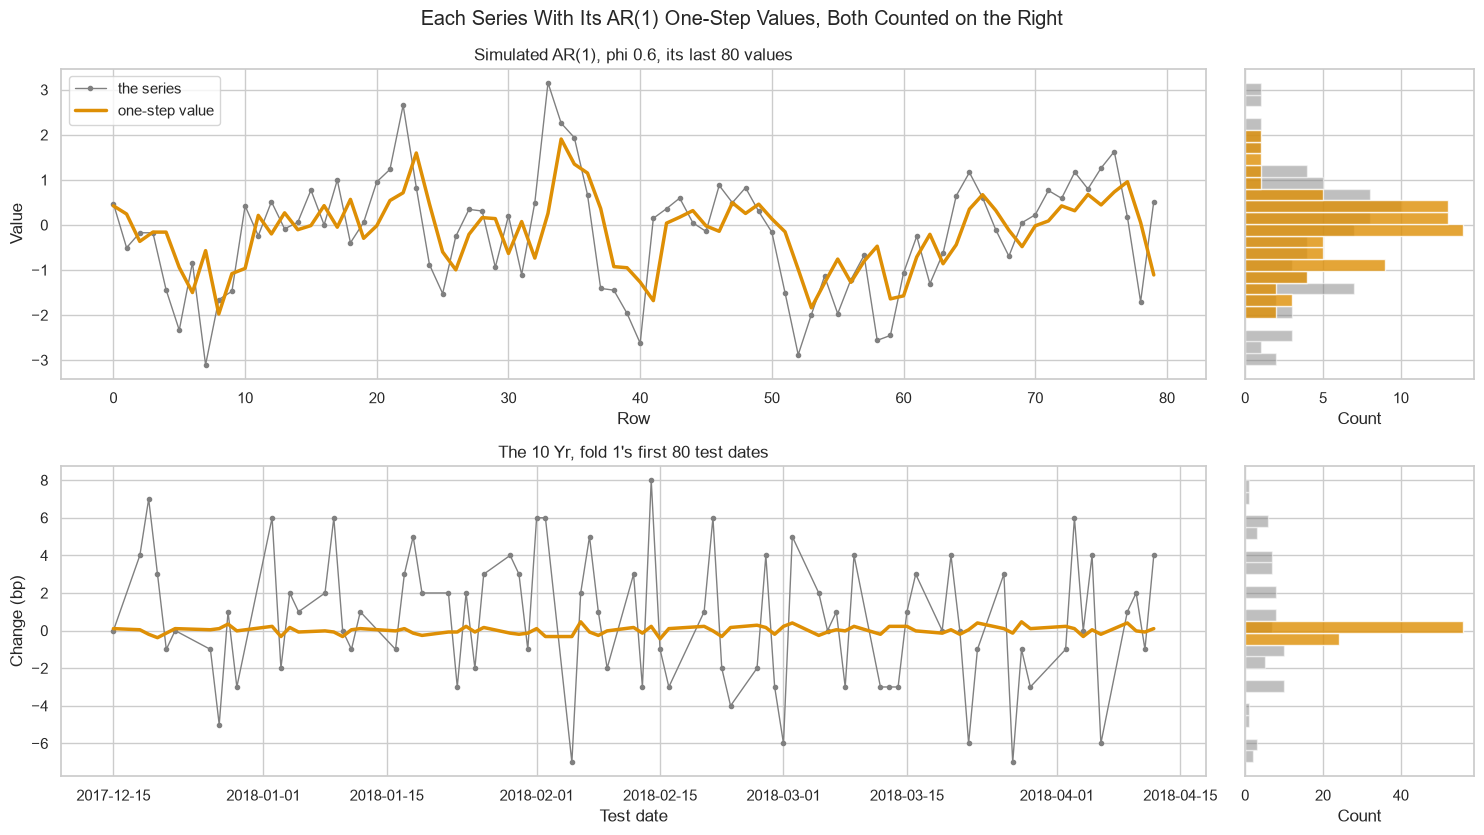

In [15]:
# each row: the series in gray, its one-step values bold, and both counted in a marginal histogram on the right
# (orientation="horizontal" lays the histogram's bars on their side, along the chart's own y axis)
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5), width_ratios=[5, 1], sharey="row")
for row, (title, x, series, values) in enumerate(panels):
    axes[row, 0].plot(x, series, color="gray", marker="o", markersize=3, linewidth=1, label="the series")
    axes[row, 0].plot(x, values, color="C1", linewidth=2.5, label="one-step value")
    bins = np.linspace(np.min(series), np.max(series), 25)
    axes[row, 1].hist(series, bins=bins, orientation="horizontal", color="gray", alpha=0.5)
    axes[row, 1].hist(values, bins=bins, orientation="horizontal", color="C1", alpha=0.8)
    axes[row, 0].set(title=title, ylabel="Value" if row == 0 else "Change (bp)", xlabel="Row" if row == 0 else "Test date")
    axes[row, 1].set(xlabel="Count")
axes[0, 0].legend(loc="upper left")
fig.suptitle("Each Series With Its AR(1) One-Step Values, Both Counted on the Right")
plt.tight_layout()
plt.show()

In [16]:
# how far each set of values spreads
print("10 Yr: changes sd", round(ten[test_dates].std(), 3), "bp | one-step values sd", round(one_step[test_dates].std(), 3),
      "bp, from", round(one_step[test_dates].min(), 2), "to", round(one_step[test_dates].max(), 2))
print("Simulated: series sd", round(simulated[-80:].std(), 2), "| one-step values sd", round(sim_one_step[-80:].std(), 2))

10 Yr: changes sd 3.481 bp | one-step values sd 0.209 bp, from -0.44 to 0.47
Simulated: series sd 1.25 | one-step values sd 0.78


On the simulated series the values follow the series: a spread of 0.78 against its 1.25.

On the 10 Yr they hug zero: a spread of 0.209 bp against the changes' 3.481, between -0.44 and 0.47 bp.

On the right, the 10 Yr's values fill the one or two bins around zero.

## The First Score

In [17]:
# the AR(1)'s MAE on all 252 of fold 1's test dates, against the last value's
fold1 = ten.index[test_rows]
print("AR(1):", round(mean_absolute_error(ten[fold1], one_step[fold1]), 3), "bp | last value:", round(ten[fold1].abs().mean(), 3), "bp")

AR(1): 2.696 bp | last value: 2.69 bp


### Interpretation of `phi`

A phi of -0.06 moves each value by 6 percent of the change before, against it.

So the values stay near zero, and score within 0.006 bp of the last value, whose fitted change is always 0.

**The fit is three lines and the values are honest. On the 10 Yr they barely move, so they cannot get much closer than zero.**

# From AR to ARIMA

Day 4 named the AR(p), which remembers the last p values, the MA(q), which keeps a part theta of each of the last q shocks, and the ARMA(p, q), which has both.
An **ARIMA(p, d, q)** first differences the series d times (Day 3), then fits an ARMA(p, q) to what is left; `order=(p, d, q)` sets the three.
An **impulse response** follows one shock through a model's later values, and `ArmaProcess(ar, ma).impulse_response(n)` gives its first n.

## One Shock Through Four Models

In [18]:
# one shock of 1 bp through four models: its effect on its own row (0) and the 5 rows after
recipes = {"AR(1), phi 0.6": ArmaProcess(ar=[1, -0.6], ma=[1]),
           "MA(1), theta 0.6": ArmaProcess(ar=[1], ma=[1, 0.6]),
           "ARMA(1, 1), both 0.6": ArmaProcess(ar=[1, -0.6], ma=[1, 0.6]),
           "The 10 Yr's AR(1)": ArmaProcess(ar=[1, -phi], ma=[1])}
responses = pd.DataFrame({name: recipe.impulse_response(6) for name, recipe in recipes.items()})

# rounded, with 0.0 added so a tiny negative prints as 0
responses.T.round(4) + 0.0

,0,1,2,3,4,5
"AR(1), phi 0.6",1.0000,0.6000,0.3600,0.2160,0.1296,0.0778
"MA(1), theta 0.6",1.0000,0.6000,0.0000,0.0000,0.0000,0.0000
"ARMA(1, 1), both 0.6",1.0000,1.2000,0.7200,0.4320,0.2592,0.1555
The 10 Yr's AR(1),1.0000,-0.0602,0.0036,-0.0002,0.0000,0.0000


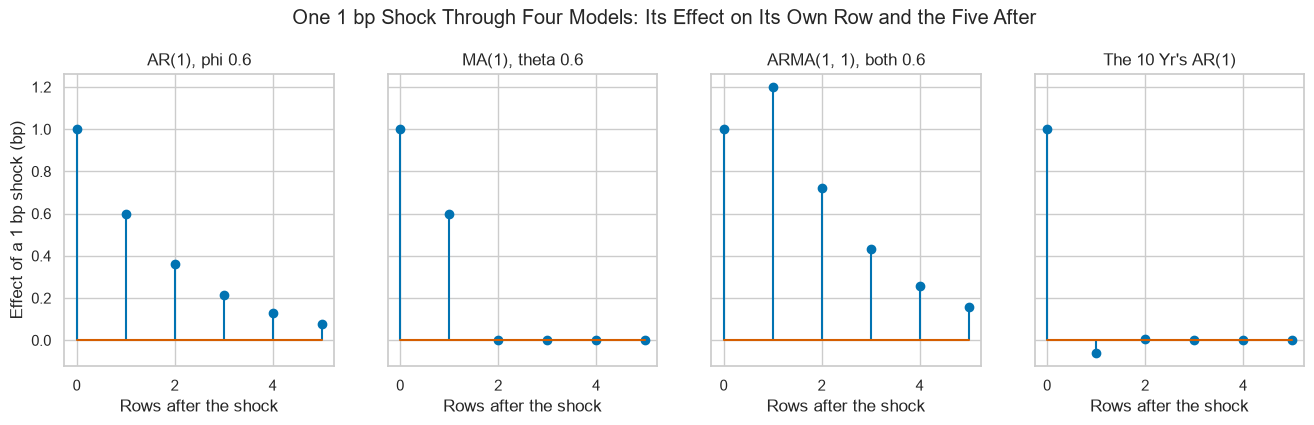

In [19]:
# each response as stems
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, name in zip(axes, responses):
    ax.stem(responses.index, responses[name])
    ax.set(title=name, xlabel="Rows after the shock")
axes[0].set_ylabel("Effect of a 1 bp shock (bp)")
fig.suptitle("One 1 bp Shock Through Four Models: Its Effect on Its Own Row and the Five After", y=1.05)
plt.show()

The AR(1) passes on 0.6 of the shock each row: 0.6, 0.36, 0.216.

The MA(1) remembers the shock for one row only, then stops.

The ARMA(1, 1) adds the two: 1.2 on the next row, then 0.6 of that each row.

The 10 Yr's AR(1) passes on -0.0602, then 0.0036: one row and it is gone.

## Differencing Inside the Model

`trend="c"` fits a constant, and `trend="n"` leaves it out.
`.append(new_values, refit=False)` runs a fitted model over new dates with its coefficients held, and `.predict(start=, end=)` reads its one-step values for those rows, each from the rows before it.

Q. Is an ARIMA(1, 1, 0) on the 10 Yr's level the same as an ARIMA(1, 0, 0) on its change?

In [20]:
# fold 1's training dates as levels (one more than the changes: the first level has no change) and as changes
fit_levels = levels["10 Yr"].loc[:fold1[0]].iloc[:-1].to_numpy()
fit_values = ten.iloc[fit_rows].to_numpy()

# the same AR(1) with no constant, d = 1 on the levels and d = 0 on the changes
on_levels = ARIMA(fit_levels, order=(1, 1, 0), trend="n").fit(method_kwargs={"warn_convergence": False})
on_changes = ARIMA(fit_values, order=(1, 0, 0), trend="n").fit(method_kwargs={"warn_convergence": False})
print("converged", on_levels.mle_retvals["converged"], on_changes.mle_retvals["converged"],
      "| phi on the levels", round(on_levels.params[0], 6), "| on the changes", round(on_changes.params[0], 6))

converged True True | phi on the levels -0.060308 | on the changes -0.060306


In [21]:
# fold 1's one-step values: a level from d = 1, less the level before; a change from d = 0
level_step = on_levels.append(levels["10 Yr"][fold1].to_numpy(), refit=False).predict(start=len(fit_levels), end=len(fit_levels) + 251)
change_step = on_changes.append(ten[fold1].to_numpy(), refit=False).predict(start=len(fit_values), end=len(fit_values) + 251)
from_levels = level_step - levels["10 Yr"].shift(1)[fold1].to_numpy()
print("Largest gap:", round(np.abs(from_levels - change_step).max(), 6), "bp | MAE:", round(mean_absolute_error(ten[fold1], from_levels), 5),
      "and", round(mean_absolute_error(ten[fold1], change_step), 5), "bp")

Largest gap: 3.7e-05 bp | MAE: 2.69718 and 2.69718 bp


The two phis agree to five decimals, the fitted changes to within 3.7e-05 bp, and the two MAEs to the last digit shown.

**An ARIMA with d = 1 on a level is the same model as d = 0 on its change. This course fits the changes, so every score is in bp of change.**

# Choosing an Order

A model with more terms reaches at least as high a log-likelihood (Course 4's Day 6) on its training dates, so a fair choice charges each fitted number a price.
An **information criterion** does that, and lower is better.
`.aic`, `.bic` and `.llf` read them from a fit:

* **AIC** = 2k less twice the log-likelihood, where k counts the fitted numbers: the constant, each phi and theta, and the shock's variance.
* **BIC** = k times ln(n) less twice the log-likelihood: on fold 1's 740 changes ln(740) is 6.6, so each term costs 6.6 against AIC's 2.

**Predict 2**

Q. Over every p and q from 0 to 4, 25 fits on fold 1's 740 training changes of the 10 Yr, which (p, q) has the lowest BIC? Write down the pair.

## The Grid of Orders

Some mixed orders give statsmodels a first guess for their AR terms that is not stationary: it warns with an `EstimationWarning` and starts from zeros.
`with warnings.catch_warnings():` around `warnings.simplefilter("ignore", EstimationWarning)` turns off that one warning inside the block and nothing else.

In [22]:
# every (p, q) from 0 to 4 on two training windows: fold 1's 740 changes and fold 5's 1,748
rows = []
# a mixed order: statsmodels' first guess for its AR terms may not be stationary, so it warns and starts from zeros
with warnings.catch_warnings():
    warnings.simplefilter("ignore", EstimationWarning)
    for window, train in [("fold 1", folds[0][0]), ("fold 5", folds[4][0])]:
        for p in range(5):
            for q in range(5):
                fit = ARIMA(ten.iloc[train].to_numpy(), order=(p, 0, q), trend="c").fit(method_kwargs={"warn_convergence": False})
                rows.append({"window": window, "p": p, "q": q, "AIC": fit.aic, "BIC": fit.bic, "log-likelihood": fit.llf,
                             "converged": fit.mle_retvals["converged"]})
grid = pd.DataFrame(rows)

In [23]:
# each window's lowest BIC, its lowest AIC among the fits that converged, and the fits that did not converge
for window, cells in grid.groupby("window"):
    bic = cells.loc[cells["BIC"].idxmin()]
    aic = cells[cells["converged"]].loc[lambda c: c["AIC"].idxmin()]
    print(window, f"| lowest BIC: ({bic.p}, {bic.q}) | lowest AIC that converged: ({aic.p}, {aic.q}) |",
          (~cells["converged"]).sum(), "of 25 did not converge")

fold 1 | lowest BIC: (0, 0) | lowest AIC that converged: (0, 1) | 6 of 25 did not converge
fold 5 | lowest BIC: (0, 0) | lowest AIC that converged: (3, 2) | 6 of 25 did not converge


In [24]:
# one heatmap: a criterion less its lowest in the window, x where the fit did not converge, the lowest outlined
def draw_grid(ax, window, criterion):
    cells = grid[grid["window"] == window]
    table = cells.pivot(index="p", columns="q", values=criterion)
    sns.heatmap(table - table.min().min(), annot=True, fmt=".1f", cmap="Blues_r", cbar=False, ax=ax)
    for cell in cells[~cells["converged"]].itertuples():
        ax.text(cell.q + 0.85, cell.p + 0.3, "x", color="C3", fontsize=14, weight="bold")
    lowest = cells.loc[cells[criterion].idxmin()]
    ax.add_patch(plt.Rectangle((lowest.q, lowest.p), 1, 1, fill=False, edgecolor="C1", linewidth=4))
    ax.set_title(f"{criterion} Above Its Lowest, {window.title()}")

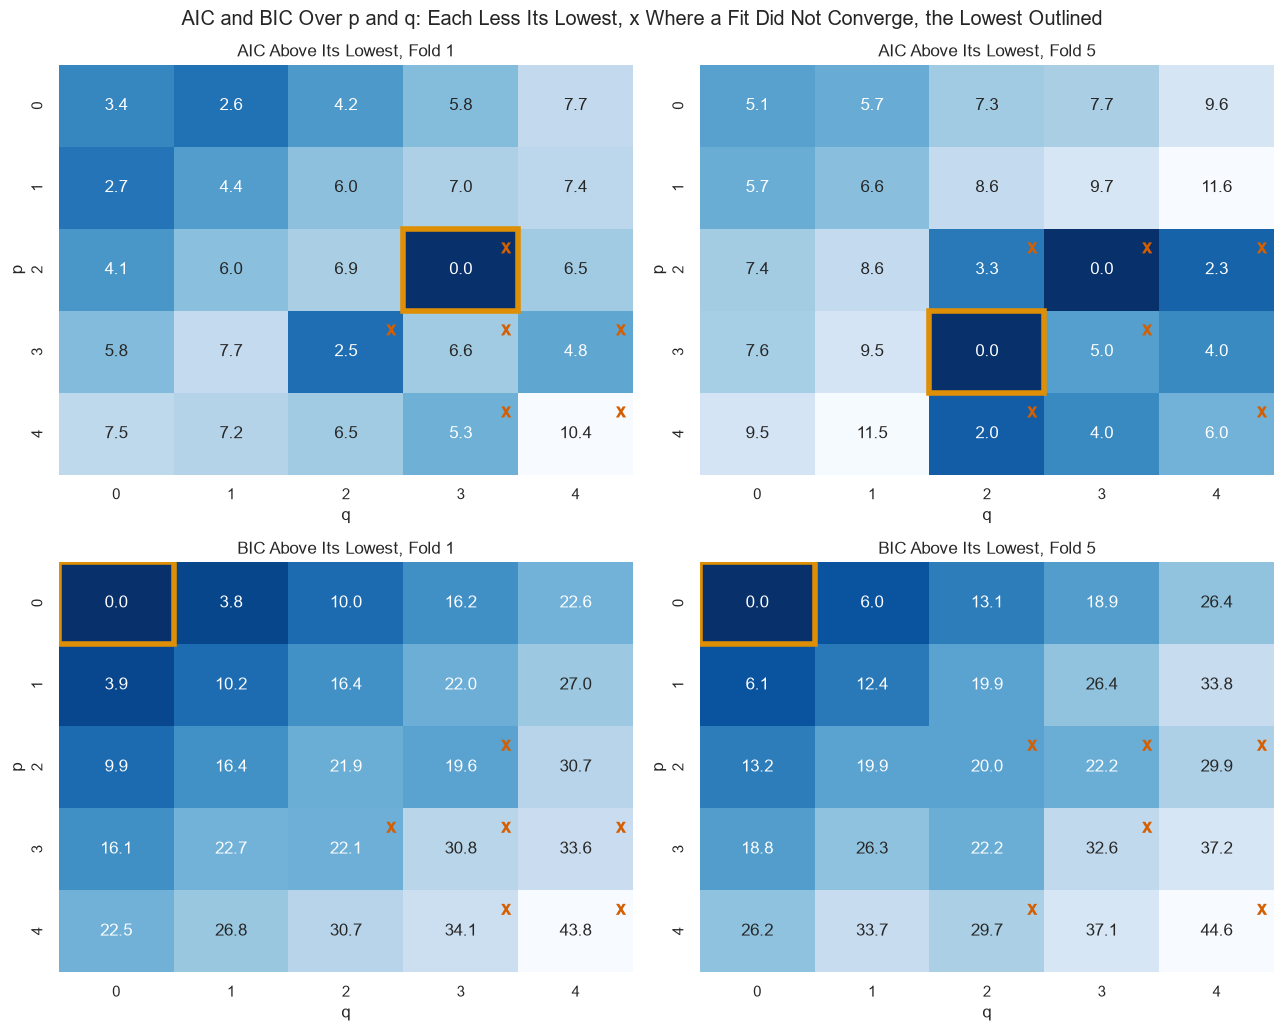

In [25]:
# the four grids: AIC on top, BIC below, fold 1 on the left, fold 5 on the right
fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))
for row, criterion in enumerate(["AIC", "BIC"]):
    for col, window in enumerate(["fold 1", "fold 5"]):
        draw_grid(axes[row, col], window, criterion)
fig.suptitle("AIC and BIC Over p and q: Each Less Its Lowest, x Where a Fit Did Not Converge, the Lowest Outlined")
plt.tight_layout()
plt.show()

BIC's lowest cell is the constant alone in both windows, and every other cell sits several points above it.

AIC's lowest cells are mixed orders, and on fold 1 its very lowest did not converge.

6 of 25 fits did not converge in each window, every one a mixed order with p and q both 2 or more.

### Interpretation of the Criteria

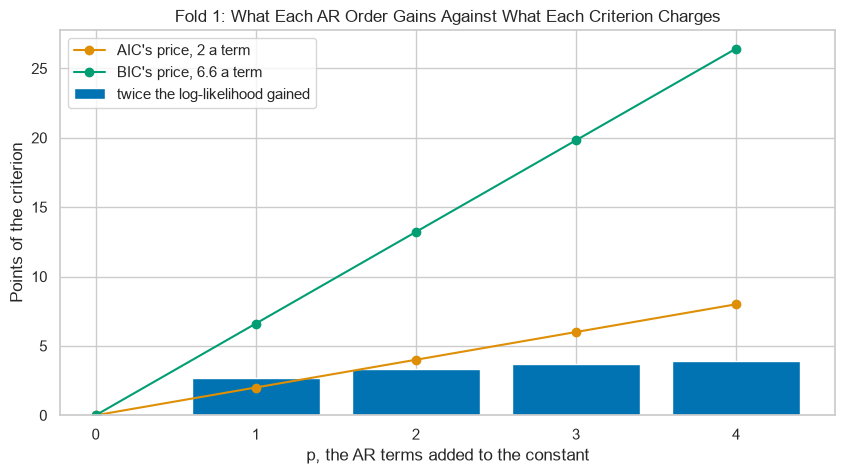

In [26]:
# fold 1: twice the log-likelihood each AR(p) gains over the constant alone, against the price each criterion charges
ar_only = grid[(grid["window"] == "fold 1") & (grid["q"] == 0)].set_index("p")
gain = 2 * (ar_only["log-likelihood"] - ar_only.loc[0, "log-likelihood"])
plt.bar(gain.index[1:], gain[1:], color="C0", label="twice the log-likelihood gained")
plt.plot(gain.index, 2 * gain.index, color="C1", marker="o", label="AIC's price, 2 a term")
plt.plot(gain.index, np.log(740) * gain.index, color="C2", marker="o", label="BIC's price, 6.6 a term")
plt.xlabel("p, the AR terms added to the constant")
plt.ylabel("Points of the criterion")
plt.title("Fold 1: What Each AR Order Gains Against What Each Criterion Charges")
plt.legend()
plt.show()

In [27]:
# the gain of each AR order, in points
gain.round(1).to_dict()

{0: 0.0, 1: 2.7, 2: 3.3, 3: 3.7, 4: 3.9}

The first lag gains 2.7 points: more than AIC's price of 2, far less than BIC's 6.6.

Each later lag gains well under a point.

## The AIC's Favourite

A model's **roots** are the numbers that make its AR part, or its MA part, equal to zero; `.arroots` and `.maroots` hold them.
A root can be a complex number, a point on a plane with `.real` and `.imag` parts, and `np.abs` gives its distance from zero.
A model whose AR roots all lie outside the **unit circle**, at a distance above 1, settles back after a shock.

In [28]:
# fold 1's lowest AIC of all 25, ARIMA(2, 0, 3), refitted with its roots
favourite = ARIMA(fit_values, order=(2, 0, 3), trend="c").fit(method_kwargs={"warn_convergence": False})
print("converged", favourite.mle_retvals["converged"])
print("AR roots", favourite.arroots.round(3), "| distances", np.abs(favourite.arroots).round(4))
print("MA roots", favourite.maroots.round(3), "| distances", np.abs(favourite.maroots).round(4))

converged False
AR roots [-0.749-0.676j -0.749+0.676j] | distances [1.009 1.009]
MA roots [-0.749-0.663j -0.749+0.663j 13.929-0.j   ] | distances [ 1.0006  1.0006 13.9286]


In [29]:
# fold 5's lowest AIC, ARIMA(3, 0, 2), the same way
late = ARIMA(ten.iloc[folds[4][0]].to_numpy(), order=(3, 0, 2), trend="c").fit(method_kwargs={"warn_convergence": False})
print("converged", late.mle_retvals["converged"])
print("AR roots", late.arroots.round(3), "| distances", np.abs(late.arroots).round(4))
print("MA roots", late.maroots.round(3), "| distances", np.abs(late.maroots).round(4))

converged True
AR roots [  0.216-1.05j   0.216+1.05j -12.968-0.j  ] | distances [ 1.0724  1.0724 12.9685]
MA roots [0.195-1.072j 0.195+1.072j] | distances [1.0898 1.0898]


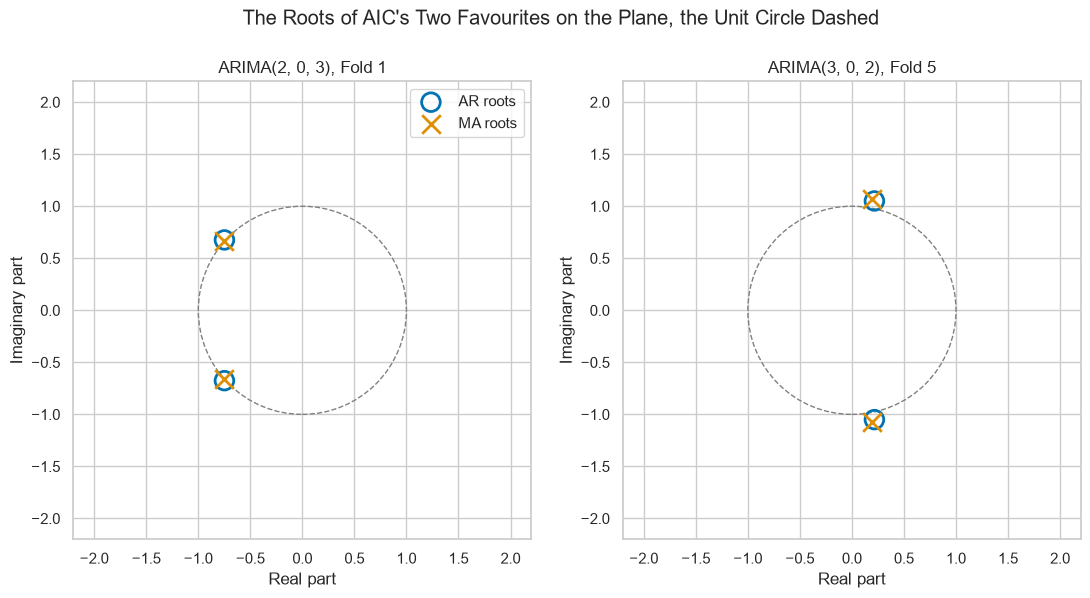

In [30]:
# each model's roots: AR roots as rings, MA roots as crosses, and plt.Circle((0, 0), 1) as the unit circle, dashed
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
for ax, (title, model) in zip(axes, [("ARIMA(2, 0, 3), Fold 1", favourite), ("ARIMA(3, 0, 2), Fold 5", late)]):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, linestyle="--", color="gray"))
    ax.scatter(model.arroots.real, model.arroots.imag, s=180, facecolors="none", edgecolors="C0", linewidths=2, label="AR roots")
    ax.scatter(model.maroots.real, model.maroots.imag, s=180, marker="x", color="C1", linewidths=2, label="MA roots")
    ax.set(title=title, xlabel="Real part", ylabel="Imaginary part", xlim=(-2.2, 2.2), ylim=(-2.2, 2.2), aspect="equal")
axes[0].legend(loc="upper right")
fig.suptitle("The Roots of AIC's Two Favourites on the Plane, the Unit Circle Dashed", y=0.98)
plt.show()

In both models a pair of AR roots sits almost on top of a pair of MA roots, just outside the unit circle.

Each model's one root left over lies about 13 from zero, off the chart.

Roots that coincide cancel: the AR part builds an echo and the MA part takes it away, so the extra terms describe nothing twice.

**BIC keeps the constant alone; AIC's best cells are terms that cancel.**

# Checking the Residuals

## The ARIMA(1, 0, 1) on Fold 5's Window

A **residual** is a change less the model's one-step value for its date: Course 4's residual, in time order.
If the model caught the memory, its residuals look like white noise.

In [31]:
# the ARIMA(1, 0, 1) on fold 5's 1,748 training changes: its coefficients, roots and residuals
late_values = ten.iloc[folds[4][0]].to_numpy()
mixed = ARIMA(late_values, order=(1, 0, 1), trend="c").fit(method_kwargs={"warn_convergence": False})
residuals = mixed.resid
print("converged", mixed.mle_retvals["converged"], "| phi", round(mixed.params[1], 4), "| theta", round(mixed.params[2], 4))
print("AR root", np.abs(mixed.arroots).round(3), "| MA root", np.abs(mixed.maroots).round(3), "| residual sd", round(residuals.std(), 3), "bp")

converged True | phi 0.5935 | theta -0.624
AR root [1.685] | MA root [1.603] | residual sd 4.488 bp


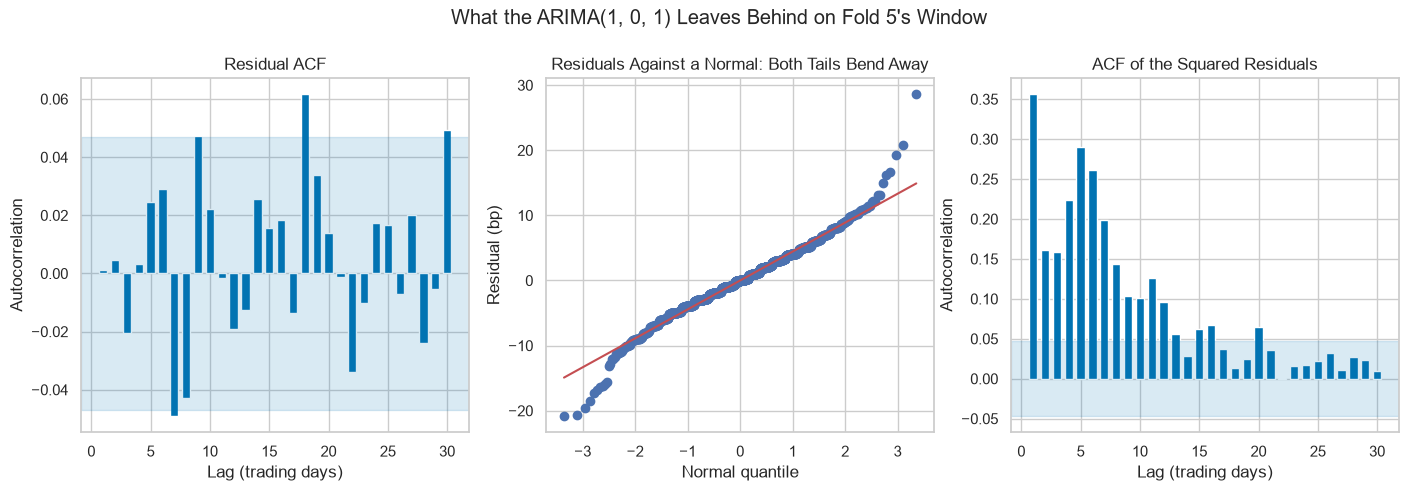

In [32]:
# the residual ACF and the squared residuals' ACF with the band, and the normal Q-Q plot (Course 4's Day 4)
late_band = 1.96 / np.sqrt(len(residuals))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, values, title in [(axes[0], residuals, "Residual ACF"), (axes[2], residuals ** 2, "ACF of the Squared Residuals")]:
    ax.bar(range(1, 31), acf(values, nlags=30)[1:], width=0.7)
    ax.axhspan(-late_band, late_band, color="C0", alpha=0.15)
    ax.set(title=title, xlabel="Lag (trading days)", ylabel="Autocorrelation")
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set(title="Residuals Against a Normal: Both Tails Bend Away", xlabel="Normal quantile", ylabel="Residual (bp)")
fig.suptitle("What the ARIMA(1, 0, 1) Leaves Behind on Fold 5's Window", y=1.03)
plt.show()

In [33]:
# bars outside the band, and the share of residuals beyond 3 standard deviations (0.27 percent for a normal)
outside = [int((np.abs(acf(values, nlags=30)[1:]) > late_band).sum()) for values in [residuals, residuals ** 2]]
print("Outside the band of", round(late_band, 4), "| residuals:", outside[0], "of 30 | squared:", outside[1], "of 30")
print("Beyond 3 sd:", round((np.abs(residuals - residuals.mean()) > 3 * residuals.std()).mean() * 100, 2), "percent")

Outside the band of 0.0469 | residuals: 4 of 30 | squared: 16 of 30
Beyond 3 sd: 0.92 percent


The residual ACF has 4 bars of 30 outside, where noise would put one or two.

The Q-Q plot bends away at both ends: 0.92 percent of residuals lie beyond 3 sd, against 0.27 for a normal.

The squared residuals put 16 of 30 bars outside: the size of a move still remembers.

### Interpretation of Ljung-Box

A fitted ARMA uses up degrees of freedom of Day 4's Ljung-Box test, one a term, and `model_df=` takes them off: `model_df=2` for phi and theta.

In [34]:
# Ljung-Box p-values on the residuals with two terms taken off, on the changes themselves, and on the squared residuals
print("Residuals:", acorr_ljungbox(residuals, lags=[10, 20], model_df=2)["lb_pvalue"].round(3).to_dict())
print("The changes, the constant alone:", acorr_ljungbox(late_values, lags=[10, 20])["lb_pvalue"].round(3).to_dict())
print("Squared residuals, 10 lags:", f'{acorr_ljungbox(residuals ** 2, lags=[10])["lb_pvalue"].iloc[0]:.1e}')

Residuals: {10: 0.049, 20: 0.061}
The changes, the constant alone: {10: 0.046, 20: 0.06}
Squared residuals, 10 lags: 2.7e-167


After the ARIMA(1, 0, 1) the p-value at 10 lags is 0.049, and on the changes themselves it was 0.046: the model removed almost nothing.

The squared residuals' p-value is 2.7e-167, Day 4's finding again, and Day 7's subject.

**The residuals look like the changes did: what is left is in their size, not their sign.**

# Model Performance Evaluation

## Walking ARIMA Forward on the 10 Yr

Day 2's walk-forward loop, as one function: each fold's ARIMA is fitted once on its training dates, then run over its test dates with its coefficients held.

In [35]:
# the walk-forward loop for any series and order: the fold MAEs in bp, every one-step value, and each fit's flag
def walk_forward_arima(series, order):
    """Fit once a fold on the training dates; keep the one-step values and the MAE on the test dates."""
    maes, values, converged = [], [], []
    for fit_rows, test_rows in folds:
        train, test = changes[series].iloc[fit_rows], changes[series].iloc[test_rows]
        # a mixed order: statsmodels' first guess for its AR terms may not be stationary, so it warns and starts from zeros
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", EstimationWarning)
            fit = ARIMA(train.to_numpy(), order=order, trend="c").fit(method_kwargs={"warn_convergence": False})
        step = fit.append(test.to_numpy(), refit=False).predict(start=len(train), end=len(train) + len(test) - 1)
        maes.append(mean_absolute_error(test, step))
        values.append(pd.Series(step, index=test.index))
        converged.append(fit.mle_retvals["converged"])
    return maes, pd.concat(values), converged

**Predict 3**

**MASE**, Day 2's score, is a model's average fold MAE over the last value's, 3.872 bp on the 10 Yr.

Q. Walked over the five folds, what is the ARIMA(1, 0, 1)'s MASE on the 10 Yr? Write down a number.

In [36]:
# four orders on the 10 Yr, walked forward: one row per order and fold
orders = [(0, 0, 0), (1, 0, 0), (2, 0, 0), (1, 0, 1)]
rows, one_step_values = [], {}
for order in orders:
    maes, one_step_values["10 Yr", order], converged = walk_forward_arima("10 Yr", order)
    for k in range(5):
        rows.append({"series": "10 Yr", "order": str(order), "fold": k + 1, "MAE": maes[k],
                     "last value": last_value["10 Yr"].iloc[k], "converged": converged[k]})
scores = pd.DataFrame(rows)

In [37]:
# per series and order: the average fold MAE, the MASE, the fits that converged, the folds below the last value
def score_table(scores):
    table = scores.groupby(["series", "order"], sort=False).agg(MAE=("MAE", "mean"), last=("last value", "mean"),
                                                                converged=("converged", "sum"))
    table["MASE"] = table["MAE"] / table["last"]
    table["folds below"] = (scores["MAE"] < scores["last value"]).groupby([scores["series"], scores["order"]], sort=False).sum()
    return table[["MAE", "MASE", "converged", "folds below"]]

score_table(scores)

MAE   MASE  converged  folds below
series order                                          
10 Yr  (0, 0, 0) 3.8795 1.0019          5            0
       (1, 0, 0) 3.8856 1.0035          5            0
       (2, 0, 0) 3.8886 1.0042          5            0
       (1, 0, 1) 3.8863 1.0036          5            0

Every order's MASE is above 1: 1.0019 for the constant alone up to 1.0042.

Every fit converged, and no fold scores below the last value.

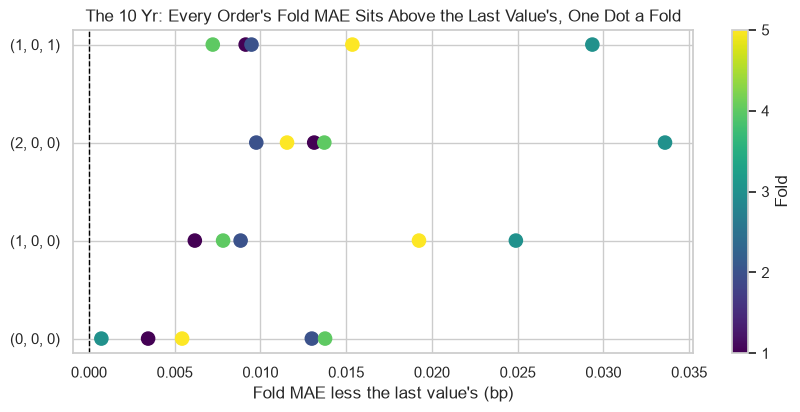

In [38]:
# each order's fold MAEs less the last value's, a dot per fold coloured by fold, 0 dashed
gaps = scores["MAE"] - scores["last value"]
plt.figure(figsize=(10, 4.2))
plt.scatter(gaps, scores["order"], c=scores["fold"], cmap="viridis", s=90)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.colorbar(label="Fold", ticks=range(1, 6))
plt.xlabel("Fold MAE less the last value's (bp)")
plt.title("The 10 Yr: Every Order's Fold MAE Sits Above the Last Value's, One Dot a Fold")
plt.show()

Every dot sits right of 0, within 0.034 bp of it.

The last value's own folds disagree by 3.567 bp, a hundred times the largest gap.

**On the 10 Yr nothing beats carrying the last value forward, and nothing loses by enough to matter either.**

# Model Performance Comparison

## The Same Four Orders on Three Series

In [39]:
# the same four orders on the 2s10s and IG, added to the 10 Yr's rows
for series in ["2s10s", "IG"]:
    for order in orders:
        maes, one_step_values[series, order], converged = walk_forward_arima(series, order)
        for k in range(5):
            rows.append({"series": series, "order": str(order), "fold": k + 1, "MAE": maes[k],
                         "last value": last_value[series].iloc[k], "converged": converged[k]})
scores = pd.DataFrame(rows)
comparison = score_table(scores)
comparison.style.format({"MAE": "{:.4f}", "MASE": "{:.4f}"}).background_gradient(subset=["MASE"], cmap="Oranges")

MAE 
 MASE 
 converged 
 folds below 
 
 
 series 
 order 
   
   
   
   
 
 
 
 
 10 Yr 
 (0, 0, 0) 
 3.8795 
 1.0019 
 5 
 0 
 
 
 (1, 0, 0) 
 3.8856 
 1.0035 
 5 
 0 
 
 
 (2, 0, 0) 
 3.8886 
 1.0042 
 5 
 0 
 
 
 (1, 0, 1) 
 3.8863 
 1.0036 
 5 
 0 
 
 
 2s10s 
 (0, 0, 0) 
 2.5791 
 1.0048 
 5 
 1 
 
 
 (1, 0, 0) 
 2.5792 
 1.0049 
 5 
 0 
 
 
 (2, 0, 0) 
 2.5853 
 1.0073 
 5 
 0 
 
 
 (1, 0, 1) 
 2.5794 
 1.0050 
 5 
 1 
 
 
 IG 
 (0, 0, 0) 
 0.9125 
 1.0005 
 5 
 0 
 
 
 (1, 0, 0) 
 0.9163 
 1.0046 
 5 
 1 
 
 
 (2, 0, 0) 
 0.9160 
 1.0043 
 5 
 0 
 
 
 (1, 0, 1) 
 0.9151 
 1.0033 
 5 
 1

All 60 fits converged.

The 2s10s's MASE runs from 1.0048 to 1.0073, IG's from 1.0005 to 1.0046.

4 of the 60 fold scores sit below the last value, two on the 2s10s and two on IG.

## Date by Date

**Predict 4**

The 1,260 dates the folds score start on 2017-12-15.

Q. On how many of the 1,260 dates is the ARIMA(1, 0, 1)'s one-step value closer to the 10 Yr's change than the last value is? Write down a number.

In [40]:
# each scored date: +1 where the ARIMA(1, 0, 1) misses by less than the last value, -1 by more, 0 a tie
scored = changes.index[folds[0][1][0]:]
closer = pd.DataFrame({series: np.sign(three.loc[scored, series].abs() - (three.loc[scored, series] - one_step_values[series, (1, 0, 1)]).abs())
                       for series in three})
for series in three:
    print(series, "| closer on", (closer[series] > 0).sum(), "of", len(scored), "| further on", (closer[series] < 0).sum(),
          "| dates with no change:", (three.loc[scored, series] == 0).sum())

10 Yr | closer on 590 of 1260 | further on 670 | dates with no change: 124
2s10s | closer on 583 of 1260 | further on 677 | dates with no change: 194
IG | closer on 613 of 1260 | further on 647 | dates with no change: 37


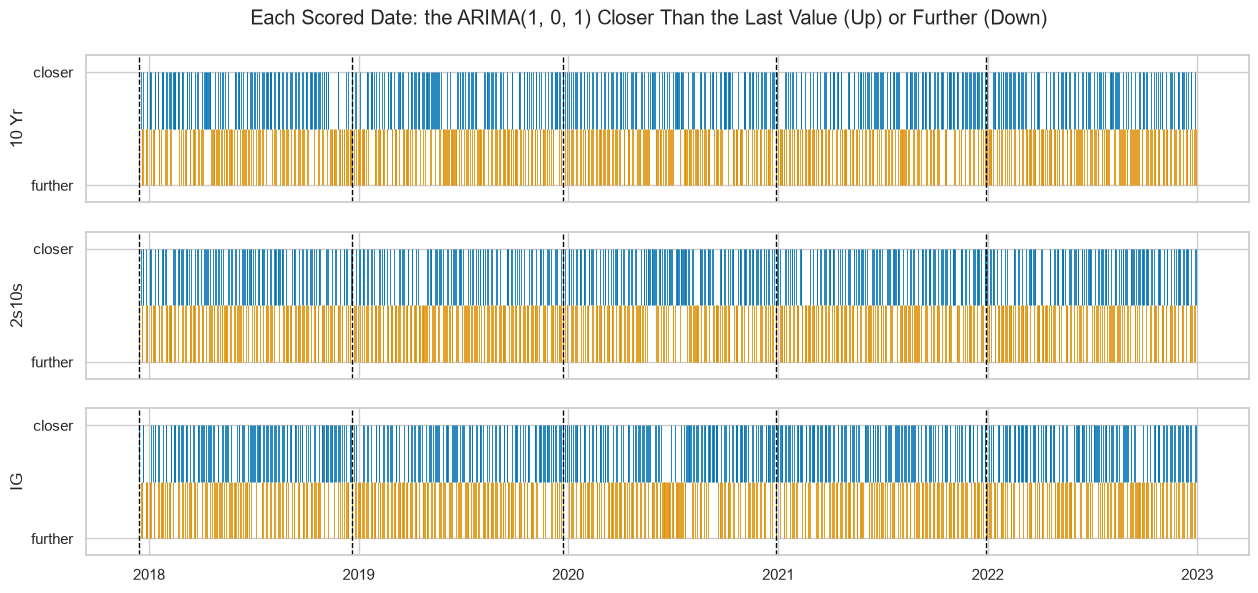

In [41]:
# a win-loss strip for each series: a tick up where the model is closer, down where it is further, fold edges dashed
fig, axes = plt.subplots(3, 1, figsize=(15, 6.5), sharex=True)
for ax, series in zip(axes, three):
    ax.vlines(scored, 0, closer[series], color=np.where(closer[series] > 0, "C0", "C1"), linewidth=0.6)
    for fold_start in scored[::252]:
        ax.axvline(fold_start, color="black", linestyle="--", linewidth=1)
    ax.set(ylabel=series, yticks=[-1, 1], yticklabels=["further", "closer"], ylim=(-1.3, 1.3))
fig.suptitle("Each Scored Date: the ARIMA(1, 0, 1) Closer Than the Last Value (Up) or Further (Down)", y=0.95)
plt.show()

The model is closer on fewer than half the dates of each series: 590, 583 and 613 of 1,260.

On the 124, 194 and 37 dates with no change the last value is exact, and the model can only be further.

Up and down ticks mix through every fold.

## How Far the Values Move

In [42]:
# on the 1,260 scored dates: the values' spread over the changes', and the share where the value has the change's sign
for series in three:
    values, actual = one_step_values[series, (1, 0, 1)], three.loc[scored, series]
    print(series, "| spread of the values over the changes':", round(values.std() / actual.std(), 3),
          "| same sign:", round((np.sign(values) == np.sign(actual)).mean() * 100, 1), "percent")

10 Yr | spread of the values over the changes': 0.049 | same sign: 46.8 percent
2s10s | spread of the values over the changes': 0.095 | same sign: 46.3 percent
IG | spread of the values over the changes': 0.109 | same sign: 48.9 percent


The values spread a twentieth to a tenth as far as the changes.

They have the change's sign on fewer than half the dates.

### Your Turn: Any Series, Any Fold

In [43]:
# one fold's test dates: the change in gray, the ARIMA(1, 0, 1)'s one-step value bold
def values_panel(ax, series, fold):
    test = changes.index[folds[fold - 1][1]]
    ax.plot(test, three.loc[test, series], color="gray", linewidth=0.8, label="the change")
    ax.plot(test, one_step_values[series, (1, 0, 1)][test], color="C1", linewidth=2, label="one-step value")
    ax.set(ylabel=f"{series} change (bp)", title=f"{series}, Fold {fold}")
    ax.legend(loc="upper left")


# your turn: pick a series and a fold
def draw_values(series="IG", fold=5):
    fig, ax = plt.subplots(figsize=(14, 4))
    values_panel(ax, series, fold)
    plt.show()

interact(draw_values, series=list(three), fold=(1, 5));

interactive(children=(Dropdown(description='series', index=2, options=('10 Yr', '2s10s', 'IG'), value='IG'), I…

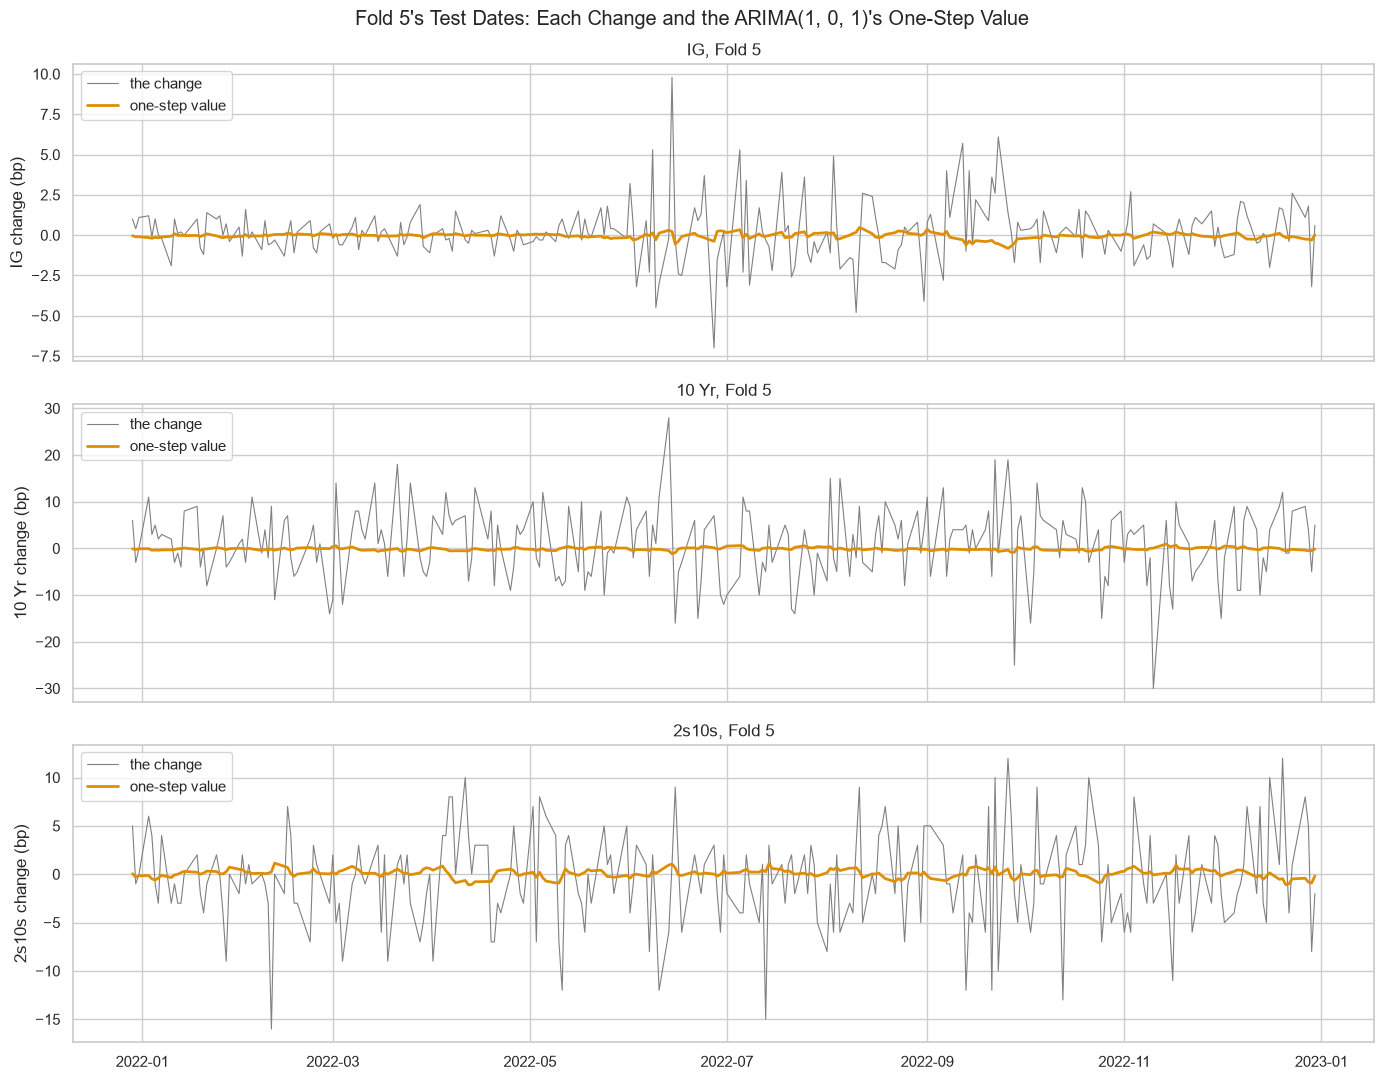

In [44]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
# with the other two series' fold 5 below it
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
for ax, series in zip(axes, ["IG", "10 Yr", "2s10s"]):
    values_panel(ax, series, 5)
fig.suptitle("Fold 5's Test Dates: Each Change and the ARIMA(1, 0, 1)'s One-Step Value")
plt.tight_layout()
plt.show()

In every series the one-step value stays near zero while the changes swing.

**Twelve models on three series: every MASE above 1, and every gap inside the fold range.**

# Insights and Conclusion

## What the Models Show, and Where They Fail

![The day's workflow as five boxes joined by arrows: fit, with AutoReg and ARIMA, giving phi, theta and a constant; choose, with AIC and BIC over a grid of p and q; check, with the residual ACF, a Q-Q plot and Ljung-Box with model_df; walk, over five folds with one fit a fold; compare, with MASE and date by date. Every model is scored against Day 2's last value carried forward on the same test dates](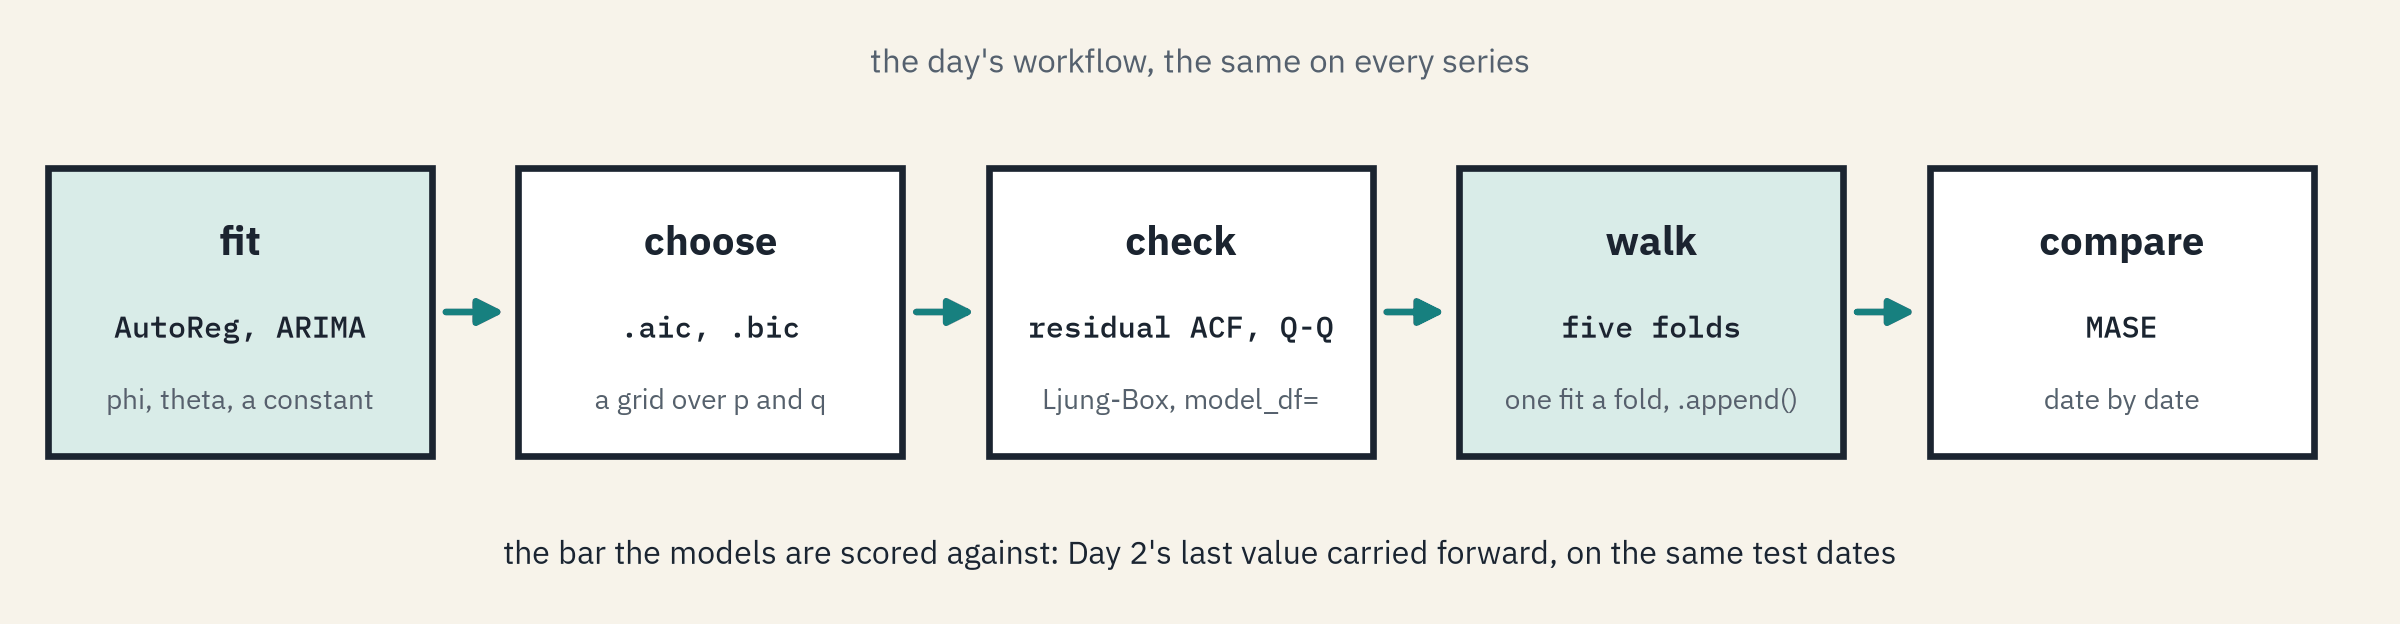)

What the models show:

* A small negative lag-1 autocorrelation on each change, and memory Ljung-Box can see at 10 lags on the 10 Yr and IG.
* On the 10 Yr, BIC chooses the constant alone, and AIC's favourites carry roots that cancel.

Where they fail:

* Their values are a twentieth to a tenth the size of the changes, and have the right sign less than half the time.
* No order beats the last value on any series, and every gap sits far inside the fold range.
* The residuals keep the memory of the size of a move.

What was not tested: another window, a refit on each date, and the held-out years.

**A test can find memory no model can use. On daily changes the last value carried forward stands until Day 7 models the size.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Fit an AR(1) by least squares and by maximum likelihood, and read phi with its standard error.
* Take one-step values from a fitted ARIMA with `.append()` and `.predict()`, and check them with the cut test.
* Set ARIMA's `order` and `trend`, and read a fit's convergence flag.
* Choose an order with AIC and BIC over a grid, and read a model's roots against the unit circle.
* Check residuals with their ACF, a Q-Q plot, and Ljung-Box with `model_df=`.
* Walk ARIMA forward on Day 2's folds, score it with MASE, and compare it with the last value date by date.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [45]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**An AR(1) on HY**

Q. Walk ARIMA(1, 0, 0) forward on `"HY"`, and store the number of folds where its MAE is below the last value's in `ex1_folds`.

In [46]:
# HY's ARIMA(1, 0, 0) walked forward, and the last value's MAE on each fold's test dates
maes, hy_values, converged = walk_forward_arima("HY", (1, 0, 0))
hy_last = [changes["HY"].iloc[test_rows].abs().mean() for fit_rows, test_rows in folds]
ex1_folds = int((np.array(maes) < np.array(hy_last)).sum())
print("Model:", np.round(maes, 4), "| last value:", np.round(hy_last, 4), "| folds below:", ex1_folds)

Model: [3.3389 3.0871 3.2409 5.0474 5.0538] | last value: [3.3321 3.0635 3.2437 5.0127 5.0329] | folds below: 1


In [47]:
check("Exercise 1 HY's folds below the last value", ex1_folds, 1)

Exercise 1 HY's folds below the last value: correct


### Exercise 2

**AIC's Pick, Walked Forward**

Q. Walk fold 5's lowest AIC, ARIMA(3, 0, 2), over the 10 Yr's five folds, and store how many of its five fits converged in `ex2_converged`. What is its MASE?

In [48]:
# fold 5's AIC pick on all five folds of the 10 Yr: each fit's flag, and the MASE
maes, picked_values, converged = walk_forward_arima("10 Yr", (3, 0, 2))
ex2_converged = sum(converged)
print("converged", converged, "| MASE", round(np.mean(maes) / last_value["10 Yr"].mean(), 4))

converged [False, True, True, True, True] | MASE 1.0013


Fold 1's fit stopped early, and the flag says so in the output.
A MASE of 1.0013 is the lowest of any order today, and still above 1.

In [49]:
check("Exercise 2 ARIMA(3, 0, 2)'s fits that converged", ex2_converged, 4)

Exercise 2 ARIMA(3, 0, 2)'s fits that converged: correct


### Exercise 3

**An AR(1) by Hand**

Q. Write `ar1_by_hand(values)`, which returns the intercept and phi of the straight line through each value against the value before, with `np.polyfit`, and store the phi of `ar1_by_hand(fit_values)` in `ex3_phi`.

In [50]:
# polyfit returns the slope first, phi, then the intercept
def ar1_by_hand(values):
    """The intercept and phi of an AR(1), by least squares."""
    phi, intercept = np.polyfit(values[:-1], values[1:], deg=1)
    return intercept, phi

ex3_phi = ar1_by_hand(fit_values)[1]
print(ex3_phi)

-0.06020813838073026


In [51]:
check("Exercise 3 the 10 Yr's phi on fold 1", ex3_phi, -0.06020813838073026)

Exercise 3 the 10 Yr's phi on fold 1: correct


### Exercise 4

**The Strongest Memory**

Q. Fit an AR(1) to the 2 Yr's fold 1 training changes with `AutoReg` and read its t, then walk ARIMA(1, 0, 0) forward on `"2 Yr"` and store its MASE in `ex4_mase`.

In [52]:
# the 2 Yr's AR(1) on fold 1's training changes, and its t
two = AutoReg(changes["2 Yr"].iloc[folds[0][0]].to_numpy(), lags=1, trend="c").fit()
print("phi", round(two.params[1], 4), "| t", round(two.tvalues[1], 2))

# walked forward: the average fold MAE over the last value's
maes, two_values, converged = walk_forward_arima("2 Yr", (1, 0, 0))
ex4_mase = np.mean(maes) / np.mean([changes["2 Yr"].iloc[test_rows].abs().mean() for fit_rows, test_rows in folds])
print(ex4_mase)

phi -0.1375 | t -3.77
1.0090383676359764


A t of -3.77 is a phi far from 0, yet its MASE of 1.009 is above 1: a phi a test can see is not a model a desk can use.

In [53]:
check("Exercise 4 the 2 Yr's AR(1) MASE", ex4_mase, 1.0090383676359764)

Exercise 4 the 2 Yr's AR(1) MASE: correct


### Exercise 5: AI check

**The Score That Was Too Large**

You asked an AI assistant for a function that scores an AR(1)'s one-step changes on the last dates of a series of levels.
This came back.
It runs.
Test it, then find the one bug.

In [54]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def one_step_mae(level, n_test=250):
    """The MAE in bp of an AR(1)'s one-step changes on the last n_test dates, fitted on the dates before them."""
    train, test = level[:-n_test], level[-n_test:]
    fit = ARIMA(train, order=(1, 0, 0), trend="c").fit(method_kwargs={"warn_convergence": False})
    print("converged", fit.mle_retvals["converged"])
    values = fit.append(test, refit=False).predict(start=len(train), end=len(level) - 1)
    return mean_absolute_error(np.diff(level)[-n_test:], values)

In [55]:
# the test: on a seeded walk of 1,000 levels, an honest MAE is near the size of a typical change, never twice it
walk = 200 + np.cumsum(np.random.default_rng(SEED).normal(0, 1.2, 1000))
typical = np.abs(np.diff(walk)).mean()
print("Typical change:", round(typical, 2), "bp")
mae = one_step_mae(walk)
print("MAE:", round(mae, 2), "bp")
assert mae < 2 * typical, "the MAE is far larger than a typical change"

Typical change: 0.94 bp
converged True
MAE: 164.05 bp


AssertionError: the MAE is far larger than a typical change

Q. Fix the bug, and store the fixed function's MAE on `walk` in `ex5_mae`.

In [56]:
# the fix: fit the AR(1) on the changes, so its one-step values are changes, scored against changes
def one_step_mae(level, n_test=250):
    """The MAE in bp of an AR(1)'s one-step changes on the last n_test dates, fitted on the dates before them."""
    change = np.diff(level)
    train, test = change[:-n_test], change[-n_test:]
    fit = ARIMA(train, order=(1, 0, 0), trend="c").fit(method_kwargs={"warn_convergence": False})
    print("converged", fit.mle_retvals["converged"])
    values = fit.append(test, refit=False).predict(start=len(train), end=len(change) - 1)
    return mean_absolute_error(test, values)

ex5_mae = one_step_mae(walk)
print(ex5_mae)

converged True
0.922635559258843


The assistant fitted the AR(1) on the levels, so its one-step values were levels, scored against changes near 1 bp: an MAE of 164.05 bp.
Fitted on the changes, the one-step values are changes, and the MAE of 0.92 bp sits under the typical change.

In [57]:
check("Exercise 5 the fixed MAE", ex5_mae, 0.922635559258843)

Exercise 5 the fixed MAE: correct


## Congratulations!

You fitted your first time series models, by hand, by least squares and by maximum likelihood.
You chose an order with two criteria, found AIC's favourites cancelling on the unit circle, and read what the residuals left behind.
You walked twelve models forward over three series and scored them date by date against the laziest rule there is.
You found memory a test can see that no model can use, and you can show why.
In Day 6 you meet exponential smoothing, which weighs the recent past more than the distant.

[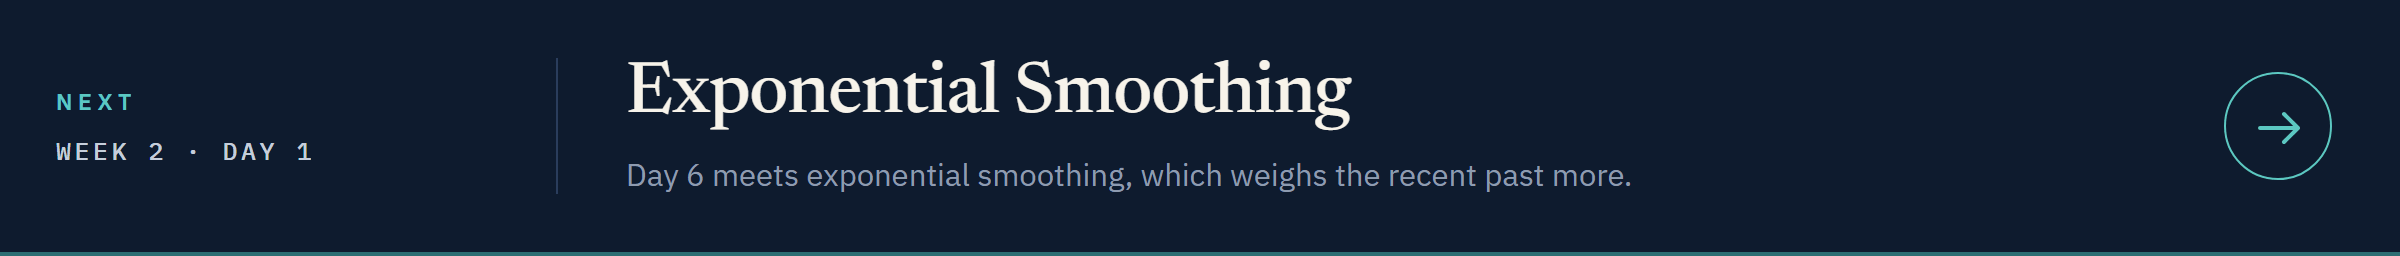](../../week2/day1/06_exponential_smoothing.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week2/day1/06_exponential_smoothing.ipynb)